# Exploring Coeliac TCRs

Looking at the sequences of the TCRs reacting to specific coeliac antigens.

In [1]:
import subprocess
from collections.abc import Iterable

import logomaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import umap
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

from tcr_pmhc_predicted_structures.clustering import calculate_sequence_distances

2026-02-26 16:51:27.724105: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
SEED = 123
CLIP_DISTANCE = 5
MIN_CLUSTER_SIZE = 4

## Sequences

In [3]:
def align_sequences(sequences: list[str]) -> list[str]:
    child = subprocess.Popen(
        [
            '/usr/bin/env',
            'mafft-linsi',
            '--quiet',
            '--op',
            '2',
            '--ep',
            '10',
            '--amino',
            '-',
        ],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
    )
    child.stdin.write('\n'.join(f'>{idx}\n{sequence}' for idx, sequence in enumerate(sequences)).encode())
    child_out = child.communicate()[0].decode('utf8')
    aligned_sequences = [line.strip() for line in child_out.split('\n') if line and not line.startswith('>')]
    child.stdin.close()

    return aligned_sequences


def make_logo_plot(cluster: pd.DataFrame) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(10, 5), gridspec_kw={'width_ratios': (1, 5, 1), 'wspace': 0.1}, sharey=True)
    fig.suptitle(f'Cluster {cluster.name} (n={len(cluster)})')

    for chain_type, axes_row in zip(('a', 'b'), axes, strict=True):
        axes_row[0].set_ylabel({'a': 'Alpha Chain', 'b': 'Beta Chain'}[chain_type], fontsize=14)

        aligned_sequences = align_sequences(cluster[f'cdr3{chain_type}'])
        probs = logomaker.alignment_to_matrix(aligned_sequences, to_type='counts')

        logomaker.Logo(probs, color_scheme='chemistry', show_spines=False, baseline_width=0.0, ax=axes_row[1])

        axes_row[1].set_xticks([])
        axes_row[1].set_yticks([])

        counts_v = cluster[f'v{chain_type}_gene'].value_counts()
        counts_j = cluster[f'j{chain_type}_gene'].value_counts()

        for ax, counts in zip([axes_row[0], axes_row[2]], [counts_v, counts_j], strict=True):
            previous_count = 0
            for gene_name, cum_count in counts.cumsum().items():
                logomaker.Glyph(0.5, gene_name[3:], previous_count, cum_count, ax=ax)
                previous_count = cum_count

            ax.set_xticks([])
            ax.set_yticks([])
            ax.spines[:].set_visible(False)


def plot_sequence_distances(
    distance_matrix: np.ndarray,
    cluster_colours: np.ndarray,
    cluster_order: np.ndarray,
    cluster_counts: np.ndarray,
    new_order: np.ndarray,
    subject_colours: np.ndarray,
    epitope_colours: np.ndarray | None = None,
    title: str | None = None,
) -> tuple[Figure, np.ndarray[Axes]]:
    if epitope_colours is not None:
        fig, axes = plt.subplots(1, 4, gridspec_kw={'width_ratios': [1, 1, 1, 20]})

    else:
        fig, axes = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

    if title:
        fig.suptitle(title)

    idx = 0

    axes[idx].imshow(subject_colours, aspect='auto')

    axes[idx].set_ylabel('Subject', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    idx += 1

    if epitope_colours is not None:
        axes[idx].imshow(epitope_colours, aspect='auto')

        axes[idx].set_ylabel('Epitope', fontsize=14)
        axes[idx].set_xticks([])
        axes[idx].set_xticklabels('')
        axes[idx].set_yticks([])
        axes[idx].set_yticklabels('')

        idx += 1

    axes[idx].imshow(cluster_colours, aspect='auto')

    axes[idx].set_ylabel('Cluster', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    accumulation = 0
    for cluster in cluster_order:
        cluster_size = cluster_counts[cluster]

        if cluster_size >= MIN_CLUSTER_SIZE:
            position = cluster_counts[cluster] // 2 + accumulation
            axes[idx].text(
                x=0.025,
                y=position,
                s=str(cluster),
                va='center',
                ha='center',
                fontsize=8,
            )

        accumulation += cluster_size

    idx += 1

    sns.heatmap(
        np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE),
        cmap='viridis_r',
        ax=axes[idx],
    )

    axes[idx].set_xlabel(r'CDR3$\alpha$', fontsize=14)
    axes[idx].set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
    axes[idx].yaxis.set_label_position('right')

    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    cbar = axes[idx].collections[0].colorbar
    cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
    cbar.set_ticks(cbar.get_ticks())
    cbar.set_ticklabels(
        [f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()]
    )

    fig.set_layout_engine('tight')

    return fig, axes

In [4]:
coeliac_sequences = pd.read_csv('../data/interim/sequences_coeliac.csv', index_col='id')

In [5]:
(
    coeliac_sequences.groupby('clone_id')['pmhc_calls']
    .apply(lambda antigens: '/'.join(sorted(set(antigens))))
    .value_counts()
)

pmhc_calls
a2       276
a1       157
w2       134
w1        66
a1/w1     42
Name: count, dtype: int64

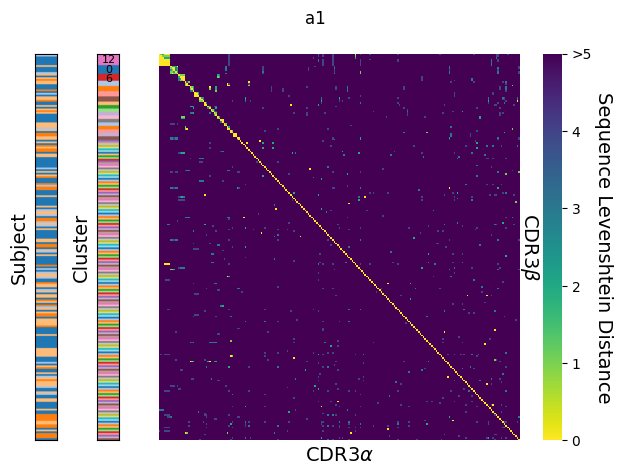

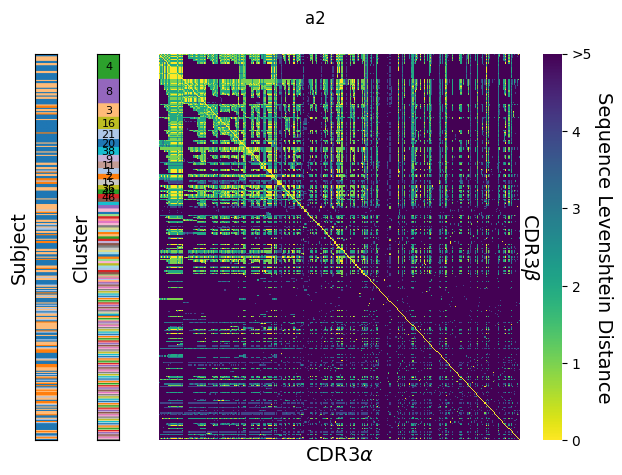

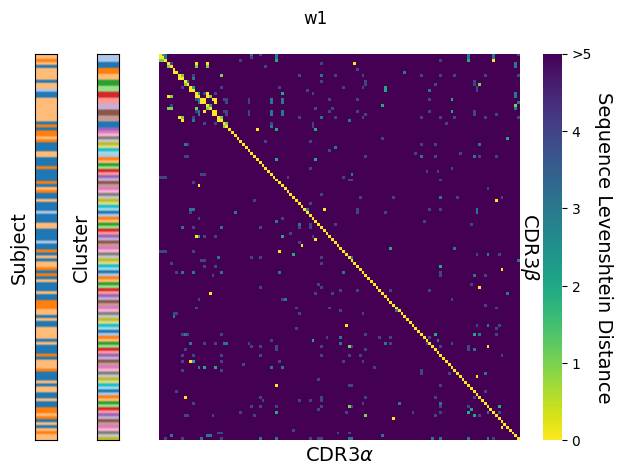

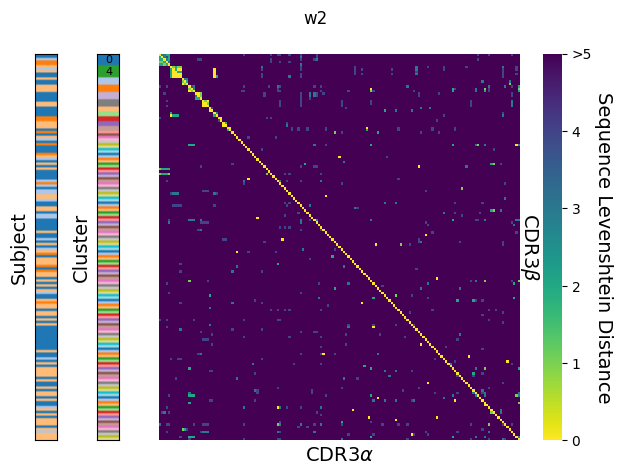

""


In [6]:
def _create_plot(group: pd.DataFrame) -> None:
    distance_matrix = calculate_sequence_distances(group['cdr3a'].tolist(), group['cdr3b'].tolist())
    cdr3_distance_matrix = distance_matrix + distance_matrix.T

    clusters = AgglomerativeClustering(
        n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
    ).fit_predict(cdr3_distance_matrix)

    cluster_counts = {}

    for cluster in clusters:
        if cluster not in cluster_counts:
            cluster_counts[cluster] = 1

        else:
            cluster_counts[cluster] += 1

    cluster_order = [
        cluster
        for cluster, _ in sorted(
            sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
        )
    ]

    new_order = []
    for cluster in cluster_order:
        (indices,) = np.where(clusters == cluster)
        new_order.extend(indices)

    new_order = np.array(new_order)

    unique_clusters = np.unique(clusters[new_order])

    palette = sns.color_palette('tab20')
    num_colours = len(palette)

    cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
    cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

    unique_subjects = sorted(group['donor_id'].unique())
    subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
    subject_colours = np.array([[subject_to_colour[subject]] for subject in group['donor_id'].to_numpy()[new_order]])

    plot_sequence_distances(
        distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours, title=group.name
    )
    plt.show()


coeliac_sequences.groupby('pmhc_calls').apply(_create_plot, include_groups=False)

In [7]:
def create_clusters(group: pd.DataFrame) -> pd.Series:
    distance_matrix = calculate_sequence_distances(group['cdr3a'].tolist(), group['cdr3b'].tolist())
    cdr3_distance_matrix = distance_matrix + distance_matrix.T

    clusters = AgglomerativeClustering(
        n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
    ).fit_predict(cdr3_distance_matrix)

    cluster_counts = {}

    for cluster in clusters:
        if cluster not in cluster_counts:
            cluster_counts[cluster] = 1

        else:
            cluster_counts[cluster] += 1

    clusters_filtered = pd.Series(
        [str(cluster) if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else 'None' for cluster in clusters],
        index=group.index,
        name='cluster',
    )

    return clusters_filtered


coeliac_sequences = coeliac_sequences.merge(
    coeliac_sequences.groupby('pmhc_calls')
    .apply(create_clusters, include_groups=False)
    .reset_index()
    .set_index('id')[['cluster']],
    how='left',
    left_index=True,
    right_index=True,
)

""


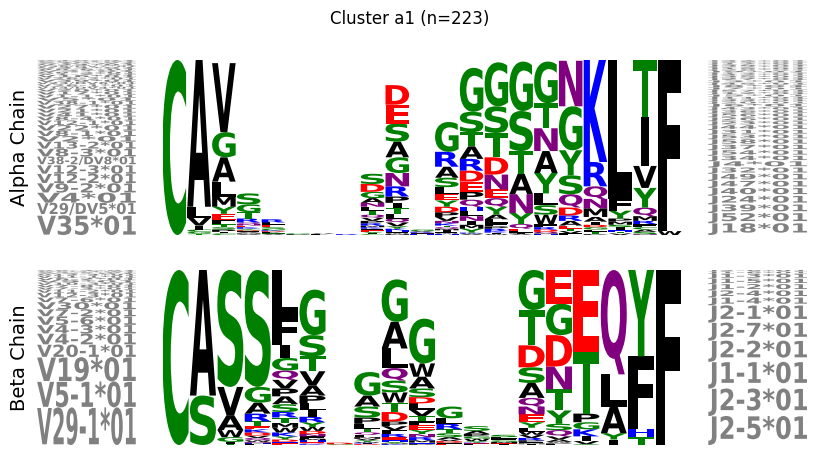

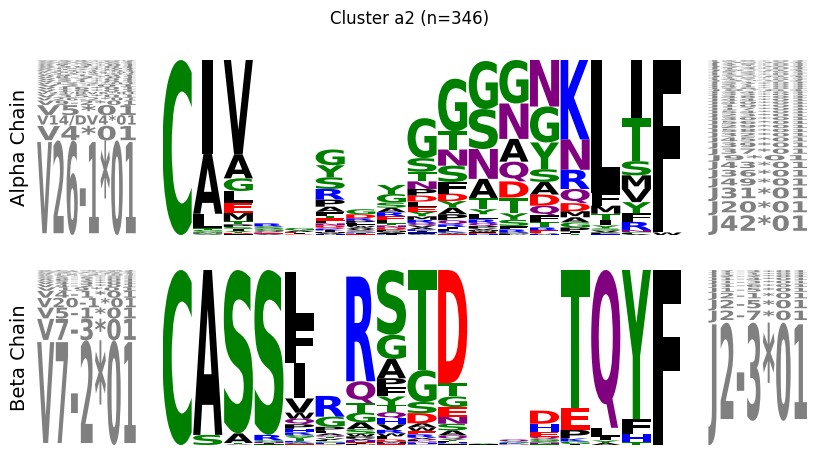

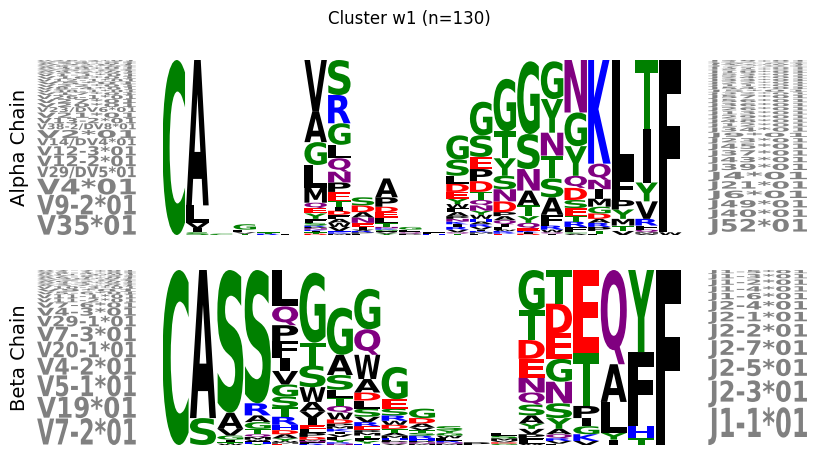

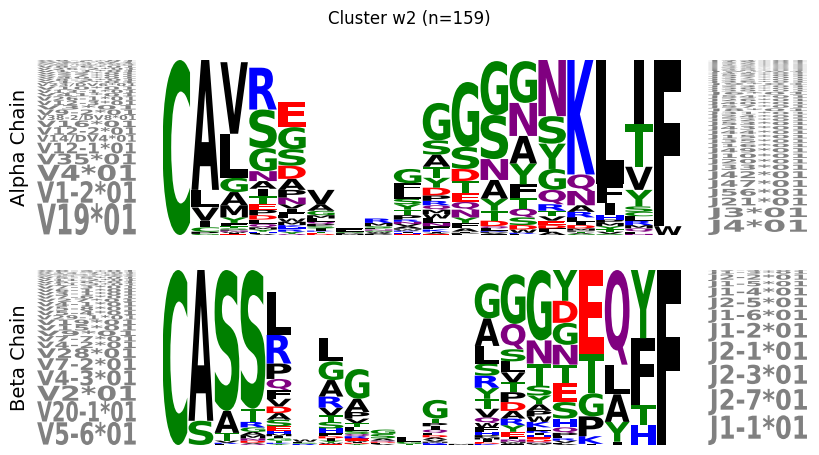

In [8]:
(coeliac_sequences.groupby(['pmhc_calls']).apply(make_logo_plot, include_groups=False))

""


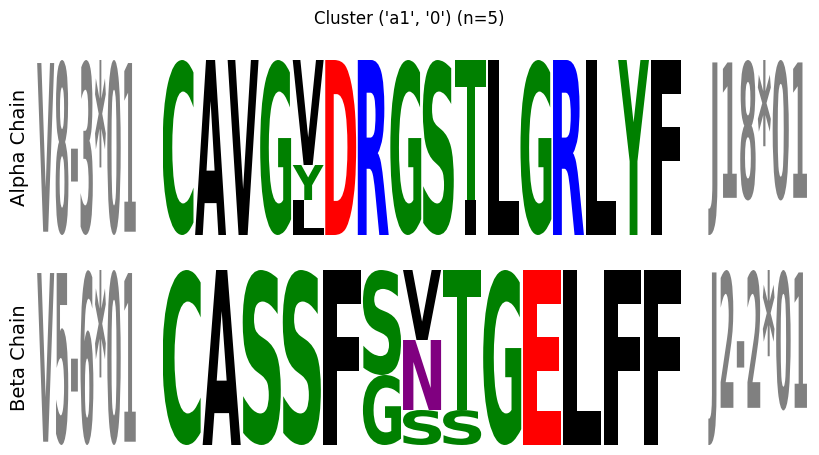

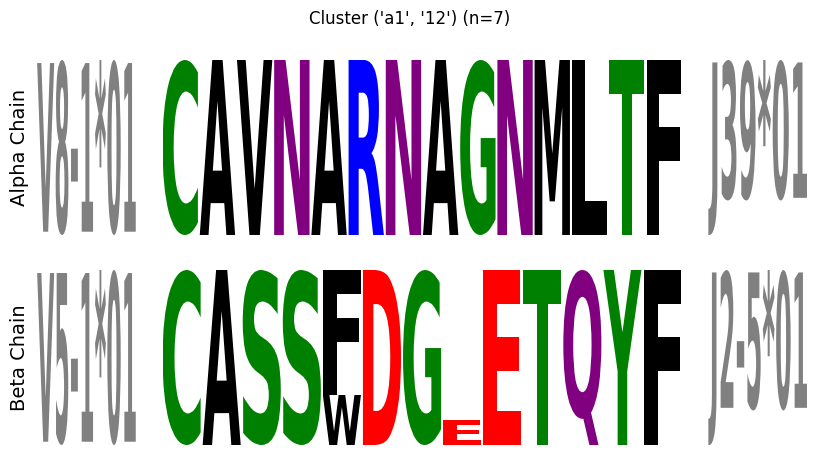

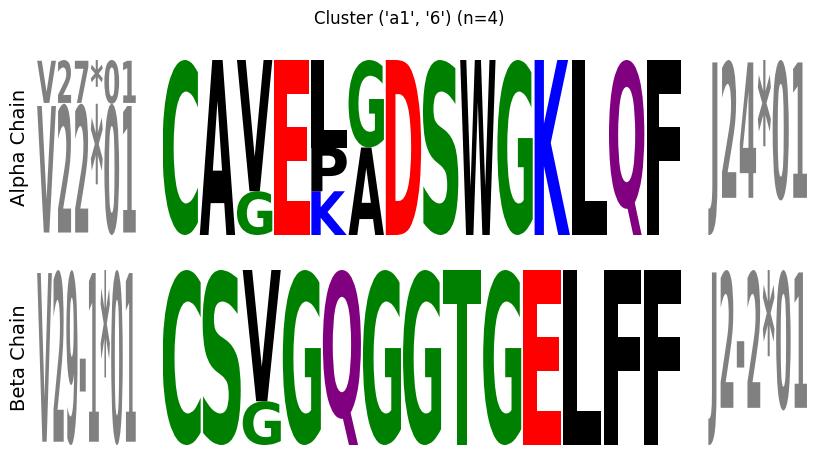

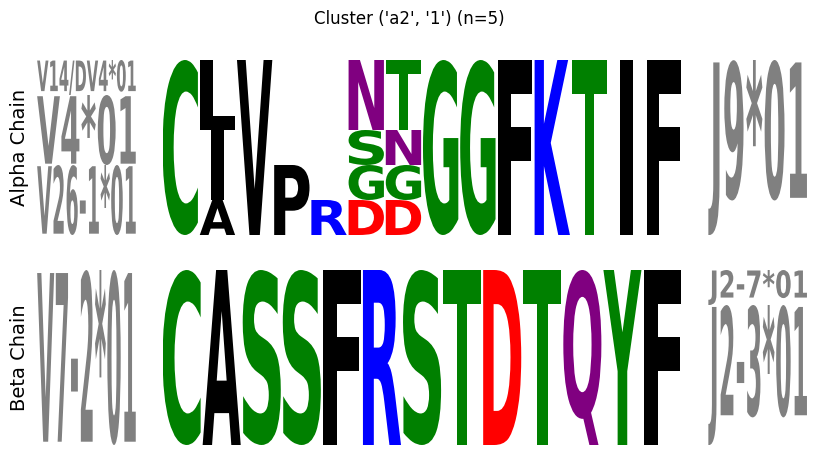

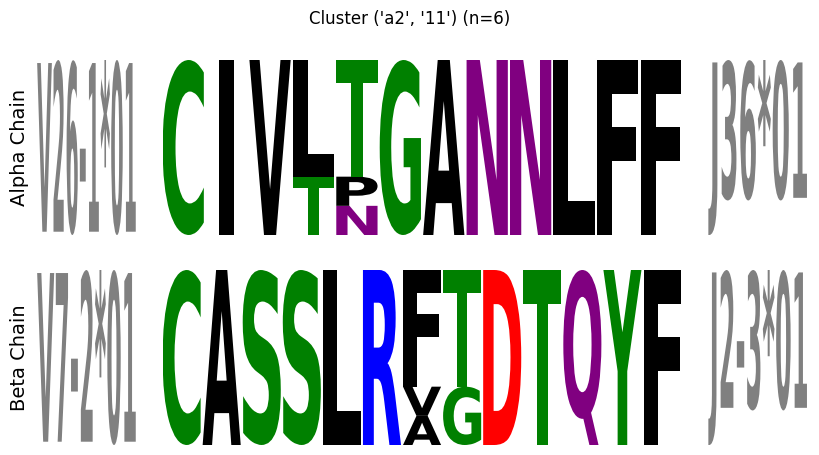

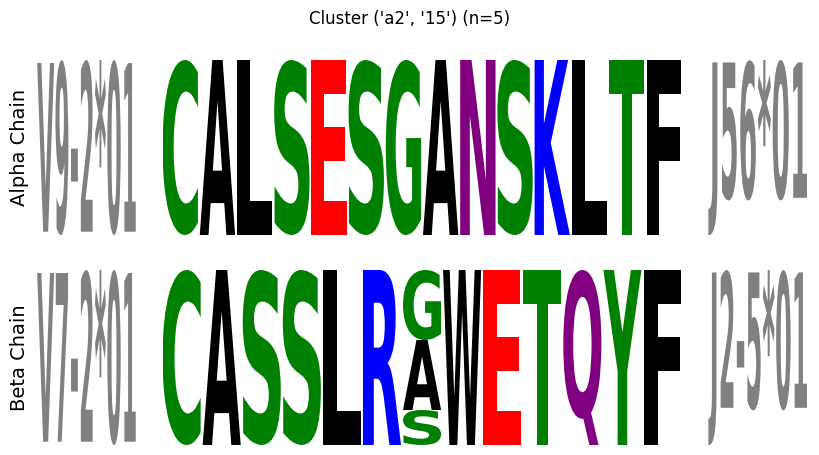

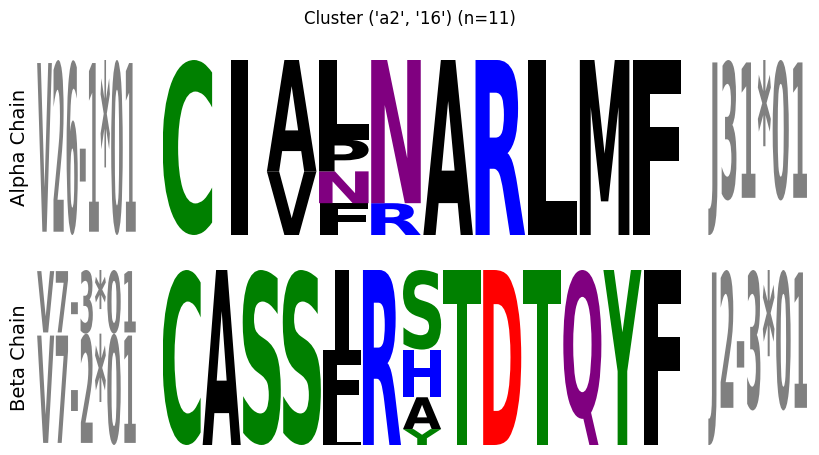

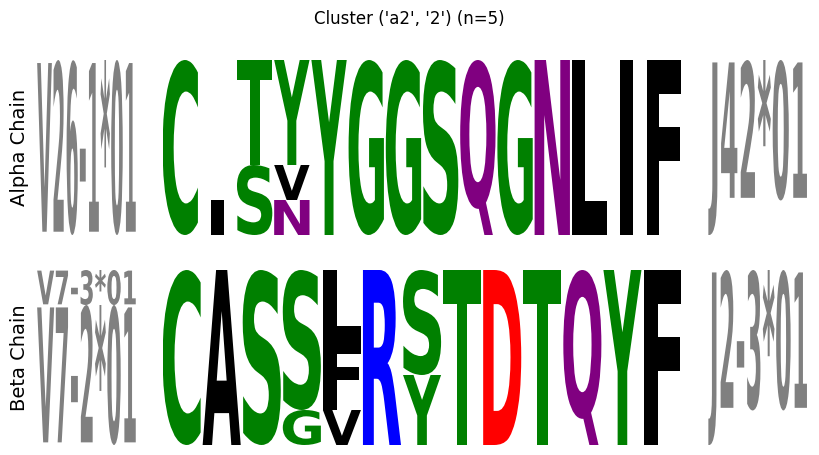

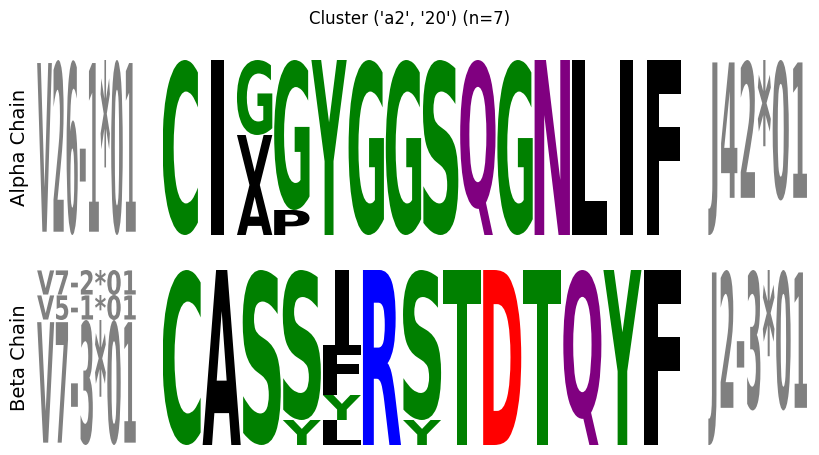

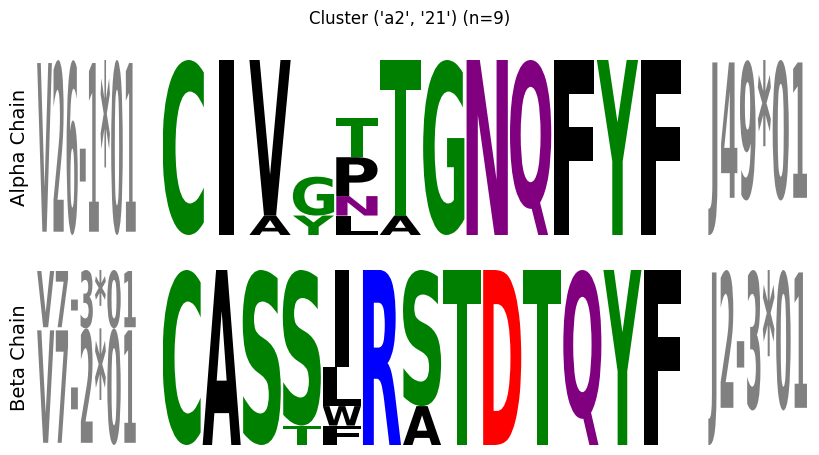

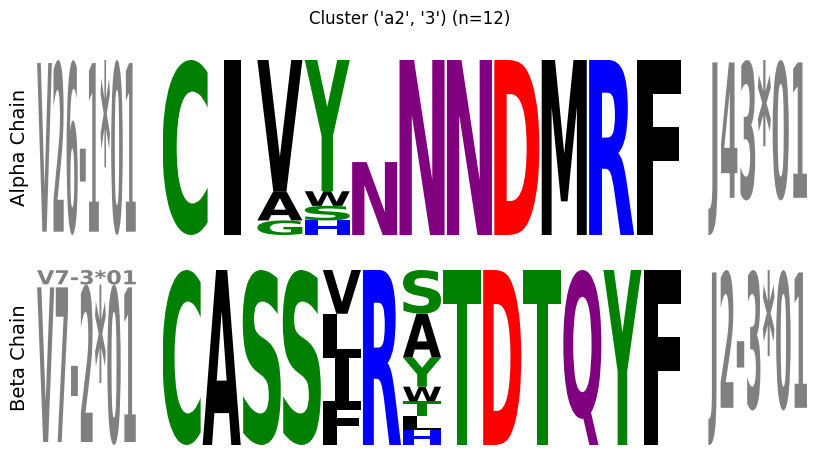

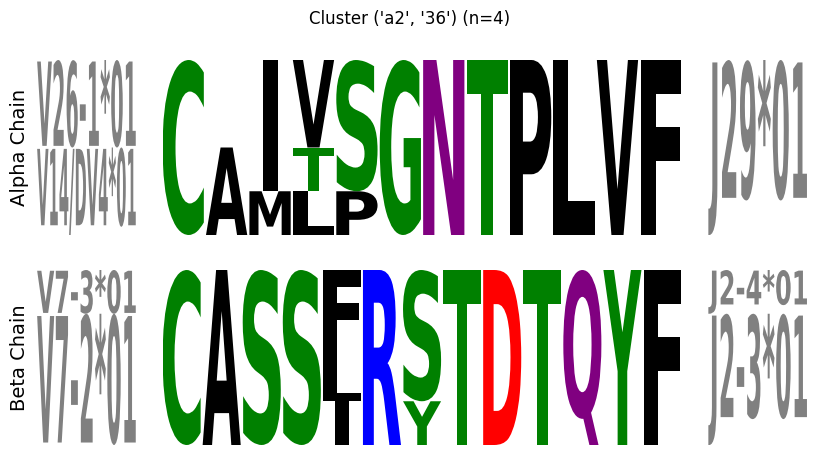

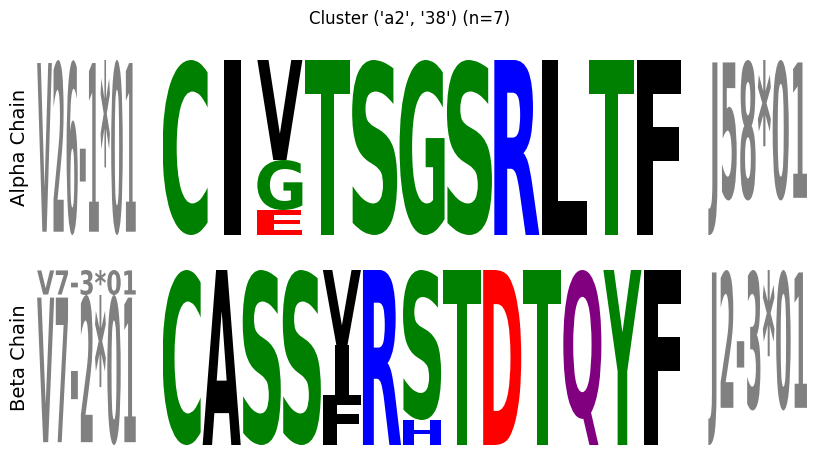

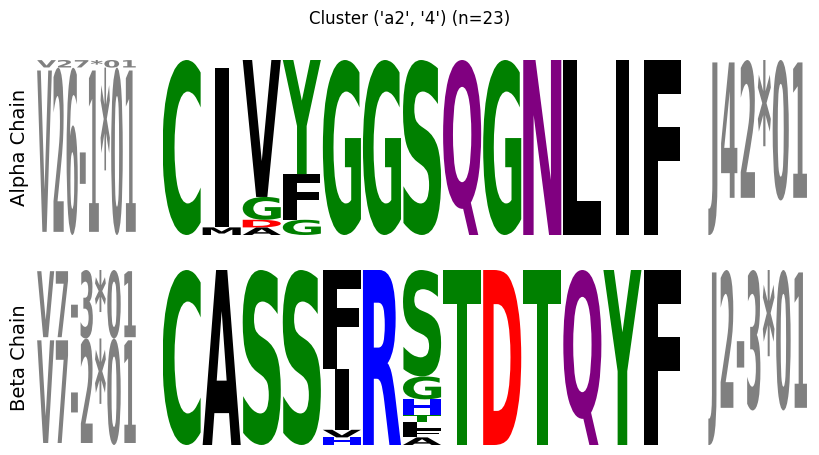

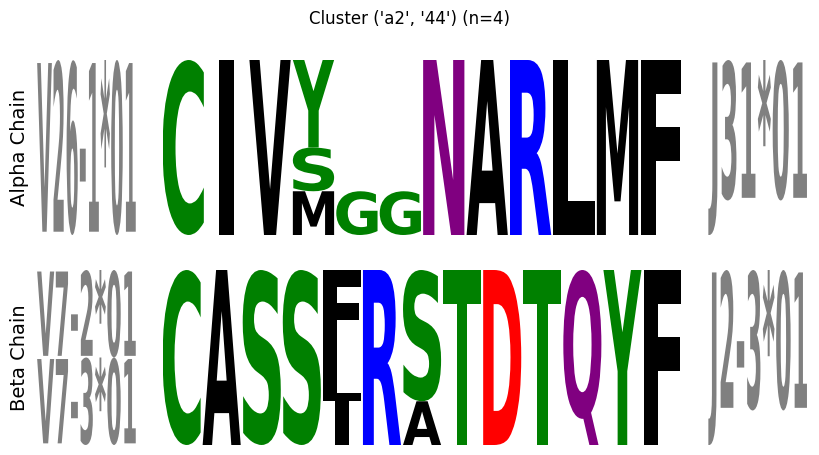

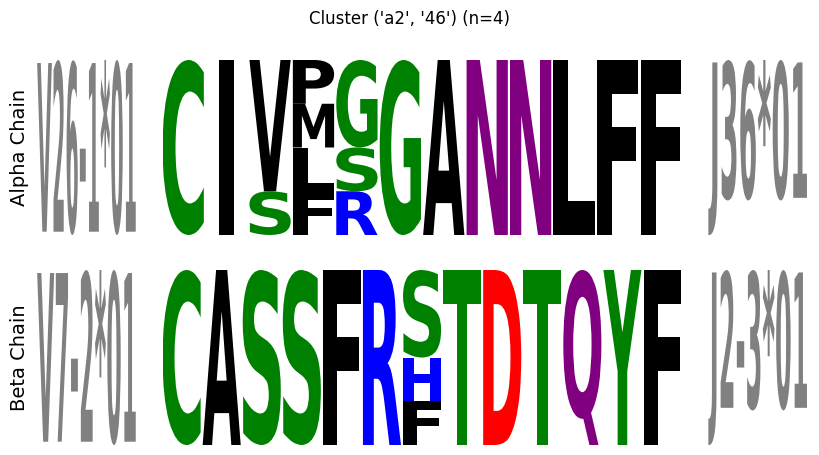

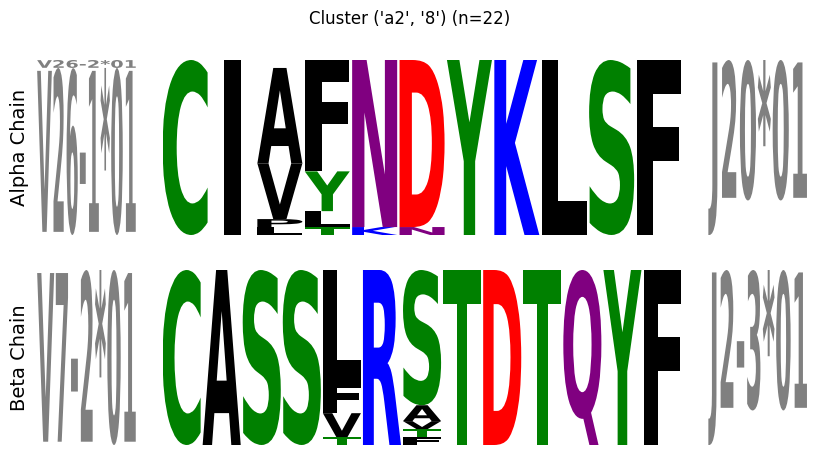

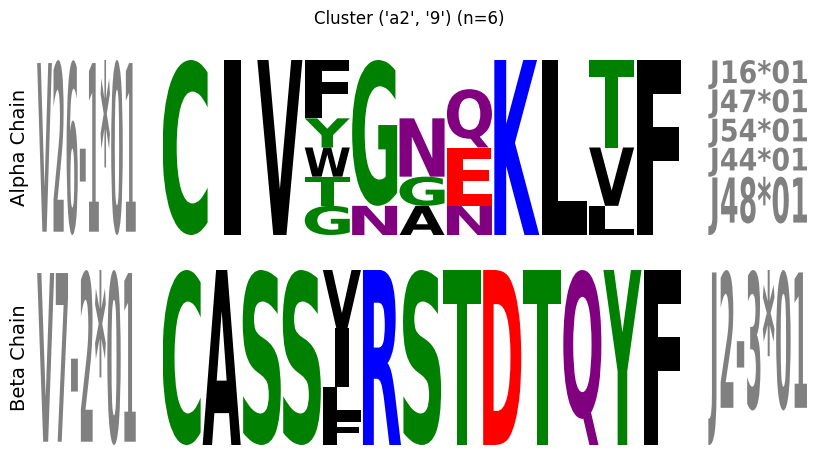

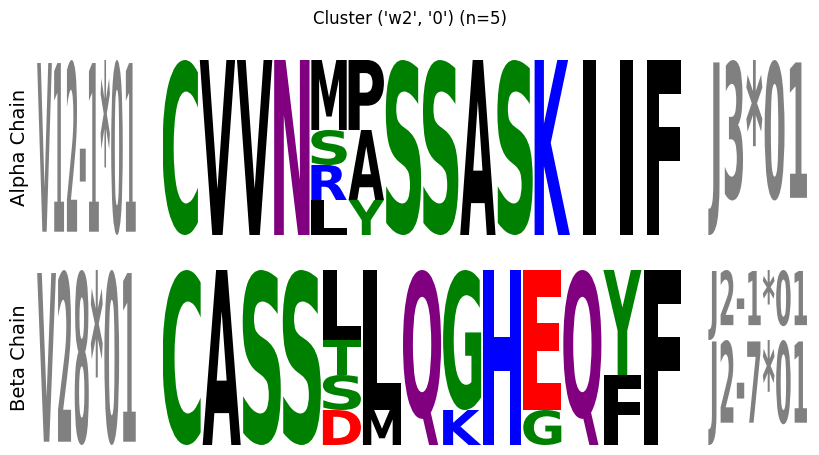

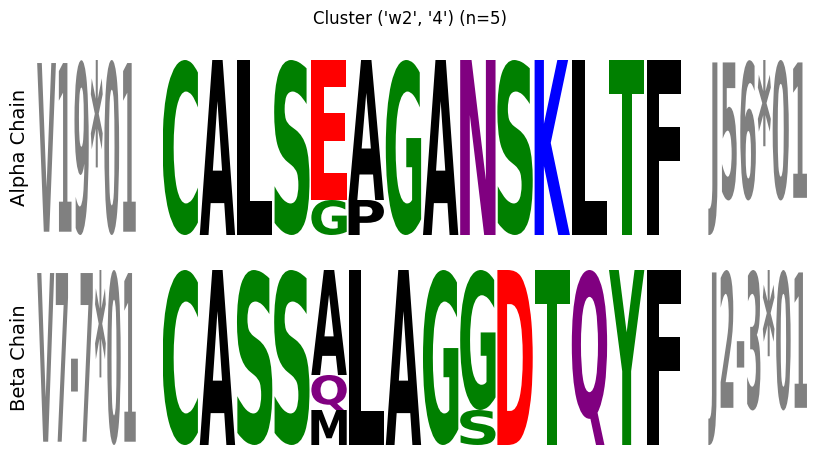

In [9]:
(
    coeliac_sequences.query("cluster != 'None'")
    .groupby(['pmhc_calls', 'cluster'])
    .apply(make_logo_plot, include_groups=False)
)

## Structures

In [10]:
def is_constant(column: pd.Series) -> bool:
    return (column == column.iloc[0]).all()


def drop_constant_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    return df[[column_name for column_name in df.columns if not is_constant(df[column_name])]]

In [11]:
def create_umap(df: pd.DataFrame, *, scale: bool = True) -> np.ndarray:
    values = df[
        [column for column in df.select_dtypes('number').columns if column not in ('seed', 'sample')]
    ].to_numpy()

    if scale:
        values = StandardScaler().fit_transform(values)

    umap_values = umap.UMAP(n_jobs=1, random_state=SEED).fit_transform(values)

    return umap_values

In [12]:
def plot_umap(umap_values: np.ndarray, hue: Iterable) -> Axes:
    ax = sns.scatterplot(x=umap_values[:, 0], y=umap_values[:, 1], hue=hue)

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    return ax


def plot_umap_clusters(umap_values: np.ndarray, info: pd.DataFrame) -> Axes:
    cluster_mask = info['cluster'] != 'None'

    ax = sns.scatterplot(x=umap_values[~cluster_mask, 0], y=umap_values[~cluster_mask, 1], color='grey')
    ax = sns.scatterplot(
        x=umap_values[cluster_mask, 0], y=umap_values[cluster_mask, 1], hue=info.loc[cluster_mask, 'cluster'], ax=ax
    )

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    return ax


def plot_umap_pmhc_call_and_clusters(umap_values: np.ndarray, info: pd.DataFrame) -> Axes:
    cluster_mask = info['cluster'] != 'None'

    ax = sns.scatterplot(
        x=umap_values[~cluster_mask, 0],
        y=umap_values[~cluster_mask, 1],
        color='grey',
    )

    ax = sns.scatterplot(
        x=umap_values[cluster_mask, 0],
        y=umap_values[cluster_mask, 1],
        hue=info.loc[cluster_mask, ['pmhc_calls', 'cluster']].apply(tuple, axis=1),
        ax=ax,
    )

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    return ax

### Structural Features

In [13]:
structural_features = pd.read_csv(
    '../data/processed/predicted_af3_af3_tcrmodel2_structural_features_sequences_coeliac.csv'
)

In [14]:
structural_features = drop_constant_columns(structural_features)
structural_features = structural_features.dropna()

In [15]:
structural_features = structural_features.merge(coeliac_sequences, how='left', left_on='name', right_index=True)

In [16]:
structural_features_umap = create_umap(structural_features)

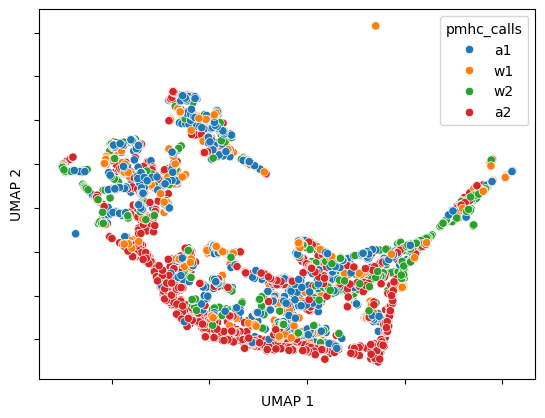

In [17]:
plot_umap(structural_features_umap, structural_features['pmhc_calls'])
plt.show()

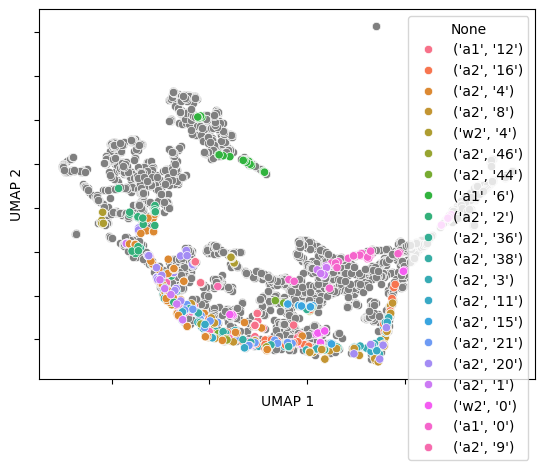

In [18]:
plot_umap_pmhc_call_and_clusters(structural_features_umap, structural_features)
plt.show()

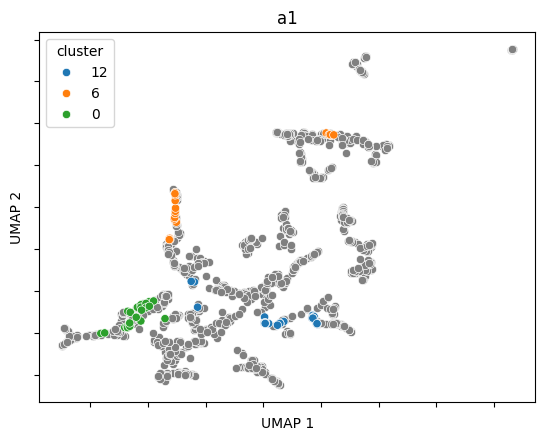

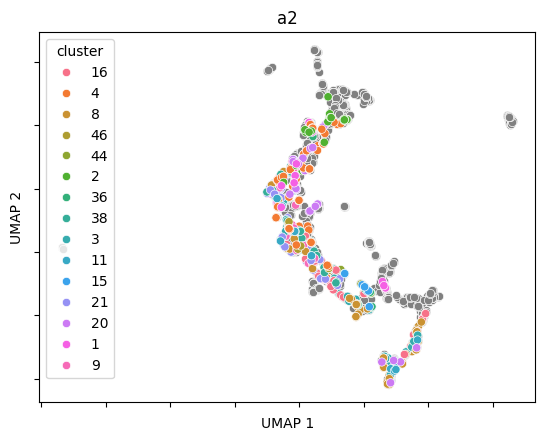

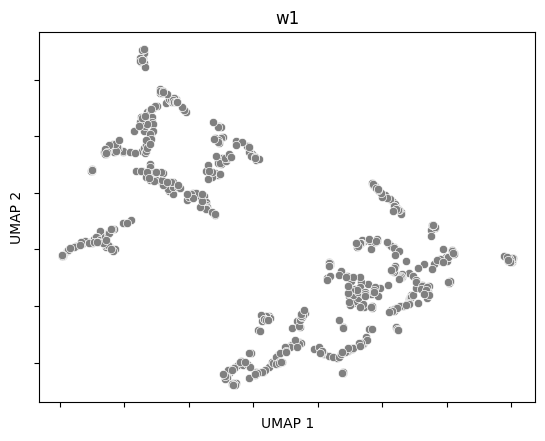

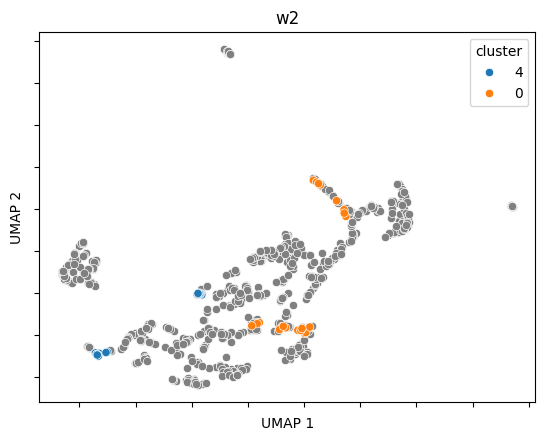

In [19]:
for antigen, group in structural_features.groupby('pmhc_calls'):
    umap_values = create_umap(group)
    ax = plot_umap_clusters(umap_values, group)
    ax.set_title(antigen)

    plt.show()

### Contact Maps

In [20]:
contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_coeliac.csv')

In [21]:
contact_maps['relative_pos_centre_tcr'] = contact_maps['relative_pos_centre_tcr'].astype(int)

In [22]:
contact_maps['resi_pmhc'] = contact_maps['resi_pmhc'].astype(str).str.replace('.0', '')

In [ ]:
contact_maps_antigens = contact_maps[contact_maps['chain_type_pmhc'] == 'antigen_chain'].copy()

In [24]:
contact_maps_antigens['relative_pos_centre_pmhc'] = contact_maps_antigens['relative_pos_centre_pmhc'].astype(int)

In [25]:
contact_map_antigens_scores = (
    contact_maps_antigens.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)
contact_map_antigens_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_antigens_scores.columns.to_flat_index()
]

In [26]:
contact_maps_mhc = contact_maps[contact_maps['chain_type_pmhc'].isin(['mhc_chain1', 'mhc_chain2'])].copy()

In [27]:
contact_map_mhc_scores = (
    contact_maps_mhc.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'chain_type_pmhc', 'resi_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'chain_type_pmhc', 'resi_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)

contact_map_mhc_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_mhc_scores.columns.to_flat_index()
]

In [28]:
contact_map_scores = pd.concat([contact_map_antigens_scores, contact_map_mhc_scores], axis=1).fillna(0).map(int)
contact_map_scores = drop_constant_columns(contact_map_scores)
contact_map_scores = contact_map_scores.reset_index()

In [29]:
contact_map_scores = contact_map_scores.merge(coeliac_sequences, how='left', left_on='name', right_index=True)

In [30]:
contact_map_scores_umap = create_umap(contact_map_scores)

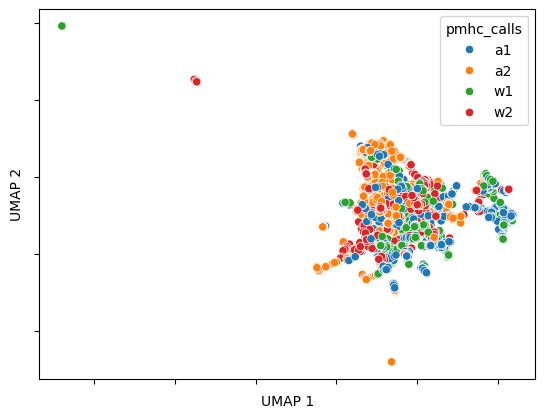

In [31]:
plot_umap(contact_map_scores_umap, contact_map_scores['pmhc_calls'])
plt.show()

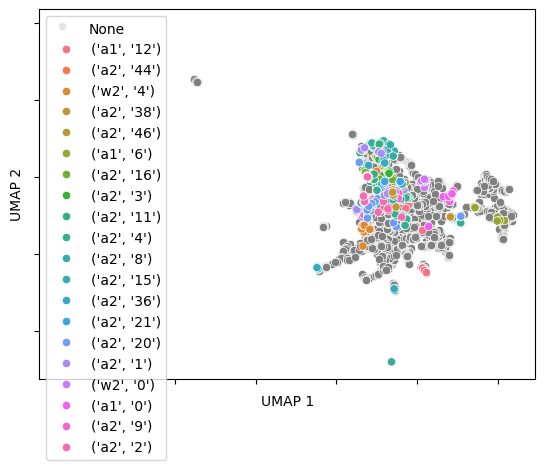

In [32]:
plot_umap_pmhc_call_and_clusters(contact_map_scores_umap, contact_map_scores)
plt.show()

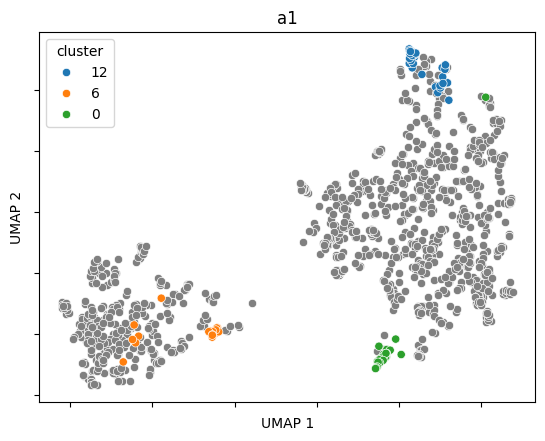

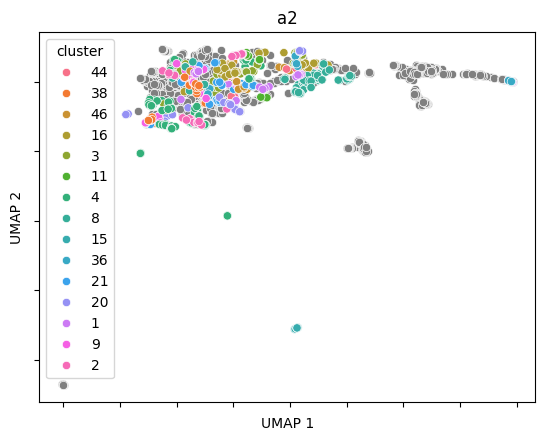

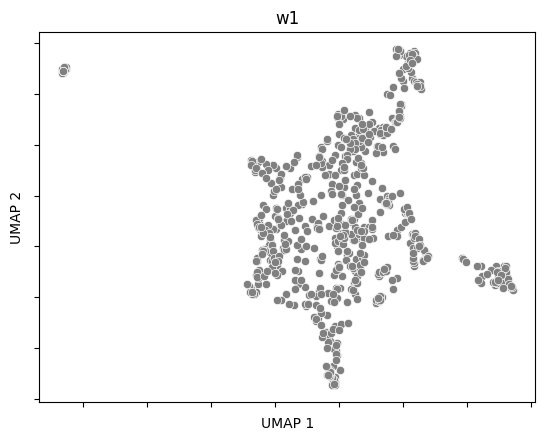

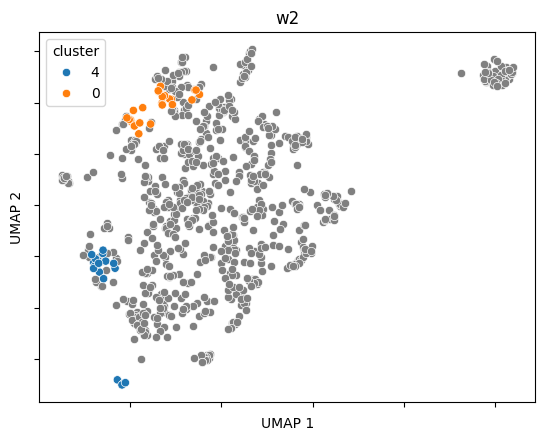

In [33]:
for antigen, group in contact_map_scores.groupby('pmhc_calls'):
    umap_values = create_umap(group)
    ax = plot_umap_clusters(umap_values, group)
    ax.set_title(antigen)

    plt.show()

### Interactions

In [34]:
interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_coeliac.csv')

In [35]:
interactions_scores = (
    interactions.groupby(['name', 'seed', 'sample'])['type']
    .value_counts()
    .reset_index()
    .pivot_table(index=['name', 'seed', 'sample'], columns='type', values='count')
    .fillna(0)
    .map(int)
)
interactions_scores = drop_constant_columns(interactions_scores)
interactions_scores = interactions_scores.reset_index()

In [36]:
interactions_scores = interactions_scores.merge(coeliac_sequences, how='left', left_on='name', right_index=True)

In [37]:
interactions_scores_umap = create_umap(interactions_scores)

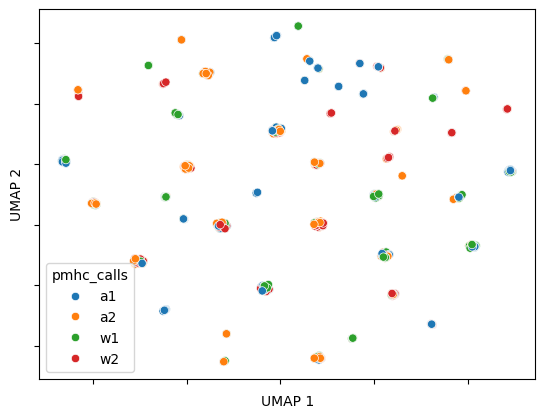

In [38]:
plot_umap(interactions_scores_umap, interactions_scores['pmhc_calls'])
plt.show()

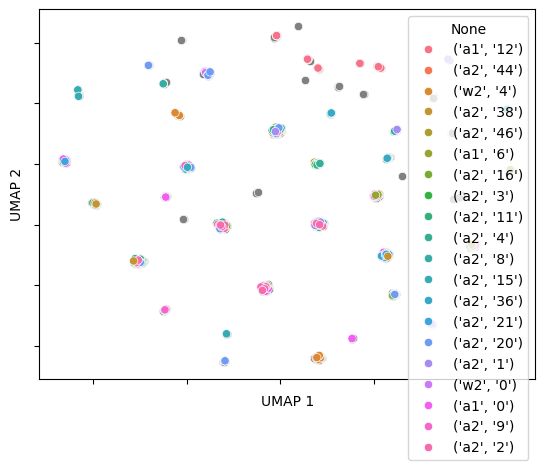

In [39]:
plot_umap_pmhc_call_and_clusters(interactions_scores_umap, interactions_scores)
plt.show()

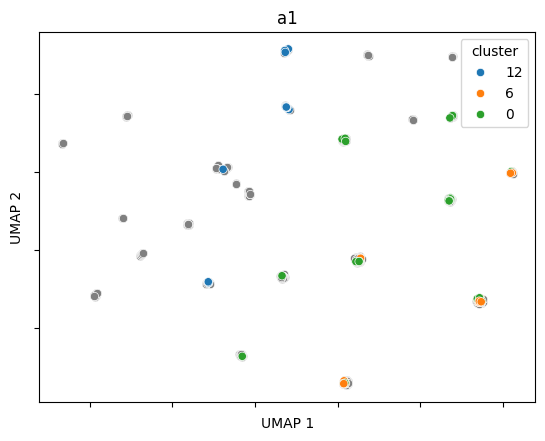

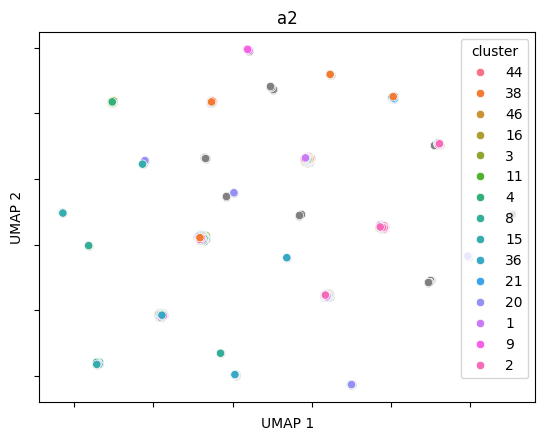

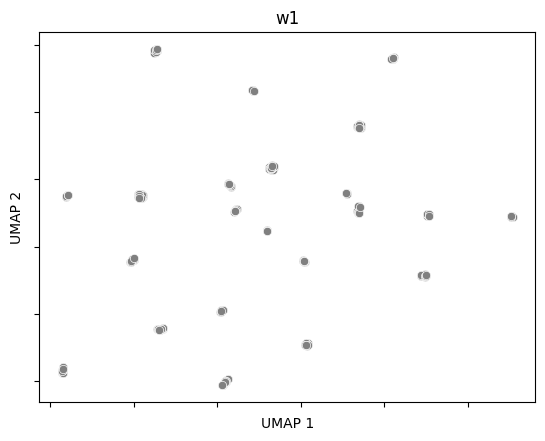

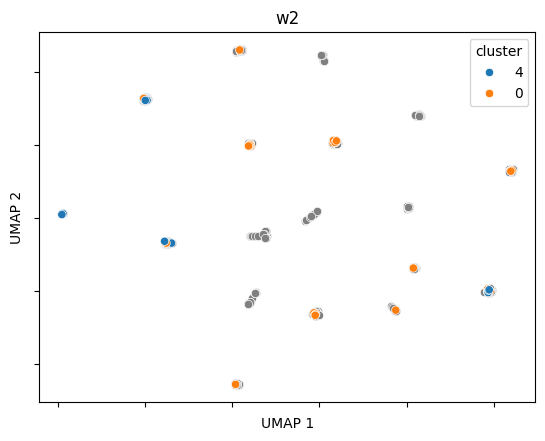

In [40]:
for antigen, group in interactions_scores.groupby('pmhc_calls'):
    umap_values = create_umap(group)
    ax = plot_umap_clusters(umap_values, group)
    ax.set_title(antigen)

    plt.show()

### Combined

In [41]:
combined_scores = structural_features.merge(contact_map_scores, how='inner').merge(interactions_scores, how='inner')

In [42]:
combined_scores_umap = create_umap(combined_scores)

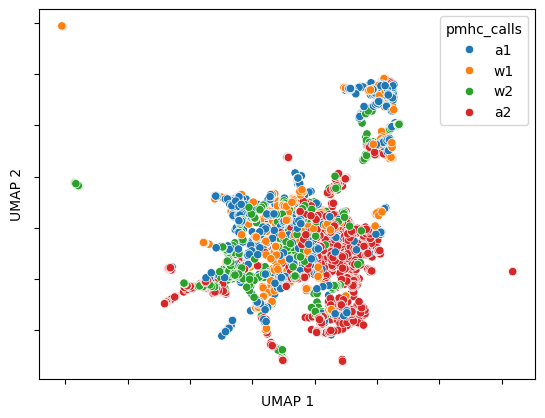

In [43]:
plot_umap(combined_scores_umap, combined_scores['pmhc_calls'])
plt.show()

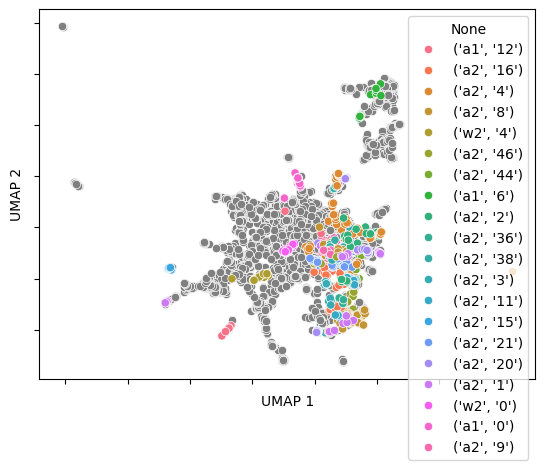

In [44]:
plot_umap_pmhc_call_and_clusters(combined_scores_umap, combined_scores)
plt.show()

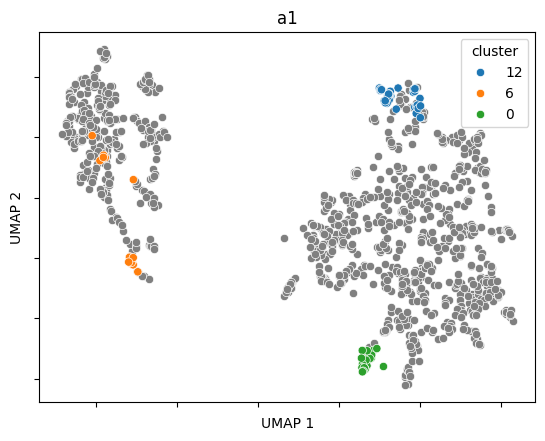

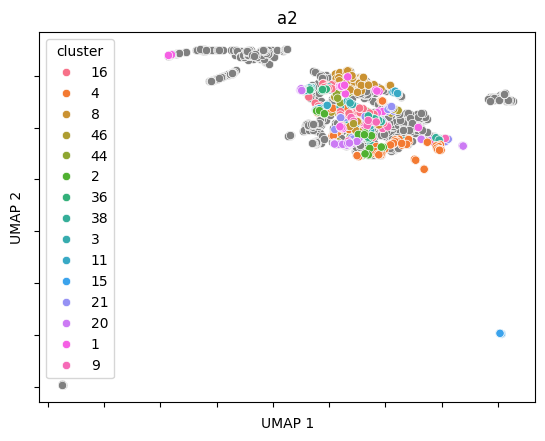

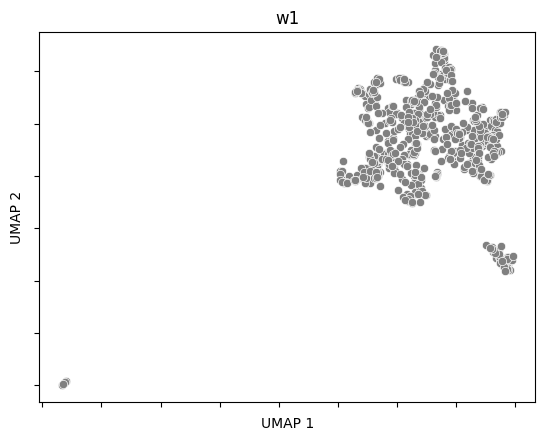

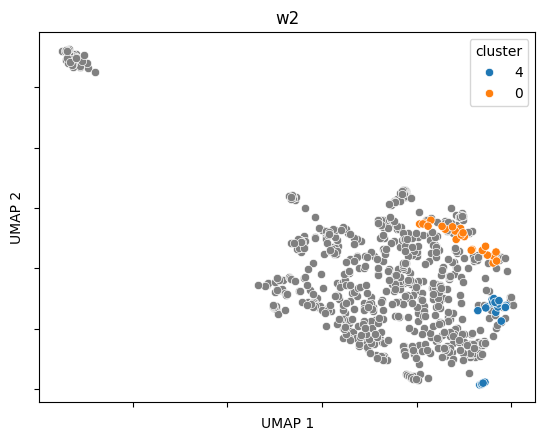

In [45]:
for antigen, group in combined_scores.groupby('pmhc_calls'):
    umap_values = create_umap(group)
    ax = plot_umap_clusters(umap_values, group)
    ax.set_title(antigen)

    plt.show()